In [3]:
import numpy as np 
import pandas as pd 

np.random.seed(23)

mu_vec1 = np.array([0,0,0])
cov_mat1 = np.array([[1,0,0],[0,1,0],[0,0,1]])
class1_sample = np.random.multivariate_normal(mu_vec1,cov_mat1,20)

df = pd.DataFrame(class1_sample,columns = ['feature 1','feature 2','feature 3'])
df['target']=1

mu_vec2 = np.array([1,1,1])
cov_mat2 = np.array([[1,0,0],[0,1,0],[0,0,1]])
class2_sample = np.random.multivariate_normal(mu_vec2,cov_mat2,20)

df1 = pd.DataFrame(class2_sample,columns = ['feature 1','feature 2','feature 3'])
df1['target']=0

df = pd.concat([df,df1],ignore_index=True)


In [4]:
df = df.sample(40)

In [5]:
df.head()

,feature 1,feature 2,feature 3,target
2,-0.367548,-1.137460,-1.322148,1
34,0.177061,-0.598109,1.226512,0
14,0.420623,0.411620,-0.071324,1
11,1.968435,-0.547788,-0.679418,1
12,-2.506230,0.146960,0.606195,1


# to plat data in 3D use plotly.express

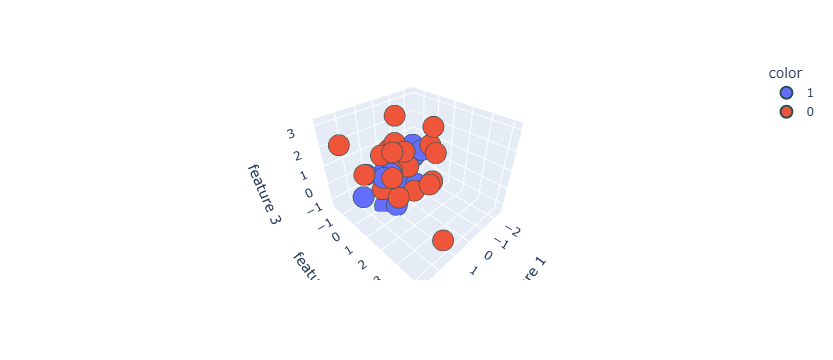

In [6]:
import plotly.express as px 
fig = px.scatter_3d(df,x=df['feature 1'],y=df['feature 2'],z=df['feature 3'],color=df['target'].astype('str'))
fig.update_traces(marker = dict(size=12,
                                line=dict(width =2 ,color='DarkSlateGrey')),
                               selector=dict(mode='markers'))
fig.show()

In [8]:
# step 1 apply standard scaling 


from sklearn.preprocessing import StandardScaler
scaler  = StandardScaler()
df.iloc[:,0:3] = scaler.fit_transform(df.iloc[:,0:3])

In [10]:
# step 2 find covariance matrix 



covariance_matrix =np.cov([df.iloc[:,0],df.iloc[:,1],df.iloc[:,2]])
print('covariance matrix is \n',covariance_matrix)

covariance matrix is 
 [[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


In [11]:
# finding eigen values and eigenvectors 


eigen_values,eigen_vectors = np.linalg.eig(covariance_matrix)



In [12]:
eigen_values

array([1.3536065 , 0.94557084, 0.77774573])

In [13]:
eigen_vectors

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442],
       [-0.52848211,  0.72025103,  0.44938304]])

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


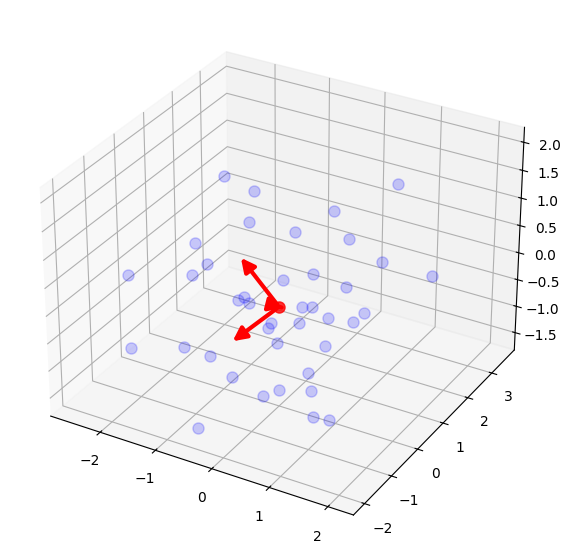

In [18]:
%pylab inline
from matplotlib import pyplot as plt 
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d import proj3d
from matplotlib.patches import FancyArrowPatch

# Updated custom class with mandatory 3D projection method
class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs 

    def do_3d_projection(self):
        # Unpack the 3D data points
        xs3d, ys3d, zs3d = self._verts3d
        # Convert 3D space vectors into 2D plane coordinates
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        # Return the minimum depth value for z-ordering calculations
        return np.min(zs)

    def draw(self, renderer):
        # Super method now uses the coordinates established in do_3d_projection
        super().draw(renderer)

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')

# Plot dataset points
ax.plot(df['feature 1'], df['feature 2'], df['feature 3'], 'o', markersize=8, color='blue', alpha=0.2)

# Calculate means
mean_x = df['feature 1'].mean()
mean_y = df['feature 2'].mean()
mean_z = df['feature 3'].mean()

# Plot center point
ax.plot([mean_x], [mean_y], [mean_z], 'o', markersize=8, color='red', alpha=0.8)

# Add eigenvectors
for v in eigen_vectors.T:
    a = Arrow3D([mean_x, mean_x + v[0]], 
                [mean_y, mean_y + v[1]], 
                [mean_z, mean_z + v[2]], 
                mutation_scale=20, lw=3, arrowstyle="-|>", color="red")
    ax.add_artist(a)

plt.show()


In [19]:
pc = eigen_vectors[0:2]

In [20]:
pc

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442]])

In [21]:
transformed_df = np.dot(df.iloc[:,0:3],pc.T)

In [23]:
new_df = pd.DataFrame(transformed_df,columns=['pc1','pc2'])
new_df['target']=df['target'].values
new_df.head()

,pc1,pc2,target
0,0.599433,1.795862,1
1,1.056919,-0.212737,0
2,-0.271876,0.498222,1
3,-0.621586,0.023110,1
4,1.567286,1.730967,1


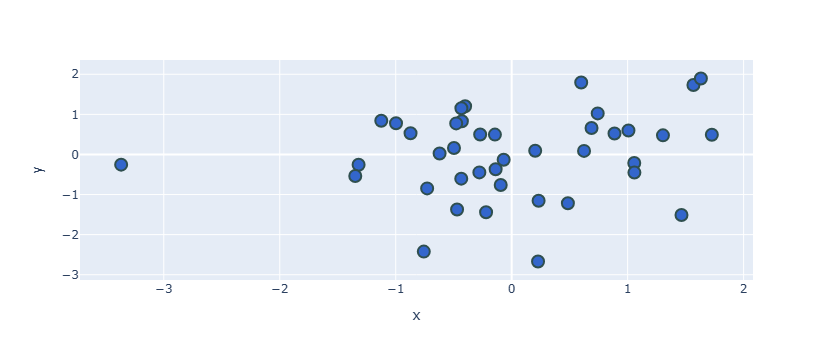

In [25]:
new_df['target']=new_df['target'].astype('str')
fig = px.scatter(x=new_df['pc1'],
                y =new_df['pc2'],
                color_discrete_sequence=px.colors.qualitative.G10)

fig.update_traces(marker = dict(size=12,line=dict(width=2,color='DarkslateGrey')),
                  selector=dict(mode='markers'))

fig.show()